In [1]:
from datetime import date

today = date.today()
print(f'Last full compilation {today}')

Last full compilation 2023-05-30


In [2]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from math import *
import os 

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100


campagnes = ['campagne_r0']
# Can be long the first time
data=read_data_from_campaigns(campagnes)
data_bulk = get_bulk_data(data)

Lecture des données réalisée en 0.00028s


r0_1


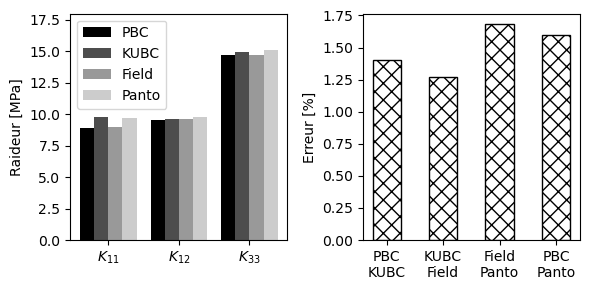

In [3]:
test=data_bulk[list(data_bulk.keys())[0]]
print(test.test_id)

plt.figure(figsize=(6,3))
plt.subplot(121)
width=0.2
x=np.linspace(0,2,3)
plt.bar(x-0.3,[test.K_plane_stress_PBC[0][0],test.K_plane_stress_PBC[1][0],test.K_plane_stress_PBC[2][2]],
        width, color='0.0', label='PBC')
plt.bar(x-0.1,[test.K_plane_stress_KUBC[0][0],test.K_plane_stress_KUBC[1][0],test.K_plane_stress_KUBC[2][2]],
        width, color='0.3', label='KUBC')
plt.bar(x+0.1,[test.K_field_dic[0][0],test.K_field_dic[1][0],test.K_field_dic[2][2]],
        width, color='0.6', label='Field')
plt.bar(x+0.3,[test.K_panto_dic[0][0],test.K_panto_dic[1][0],test.K_panto_dic[2][2]],
        width, color='0.8',  label='Panto')


plt.legend()
plt.ylabel('Raideur [MPa]')
plt.ylim(top=18)
plt.xticks(range(3), [r'$K_{11}$',r'$K_{12}$',r'$K_{33}$'])



plt.subplot(122)
width=0.5
x=np.linspace(0,3,4)

plt.bar(x,[test.global_err[0][1],test.global_err[1][2],test.global_err[2][3],test.get_error((0,3))],
        width, color='k',fill=False, hatch='xx')

plt.ylabel('Erreur [%]')
plt.xticks(range(4), ['PBC\nKUBC',
                      'KUBC\nField',
                      'Field\nPanto',
                      'PBC\nPanto'])
plt.tight_layout()
plt.savefig('images/err_mono_coef.pdf')

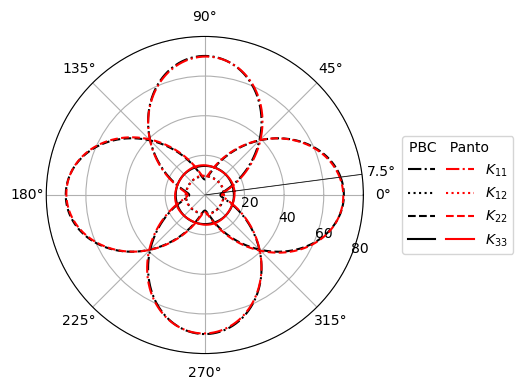

In [4]:



K_0 = np.array(test.K_plane_stress_PBC)

plt.subplots(subplot_kw={'projection': 'polar'})
offset=7.5

K_list = []
theta_list = np.arange(0, 2*pi, pi/1000)

for t in theta_list:
    angle = t
    c, s = cos(angle), sin(angle)
    T = np.array([[c**2, s**2, c*s],
                [s**2, c**2, -c*s],
                [-2*s*c, 2*c*s, (c**2-s**2)]])
    K = np.dot(np.dot(np.transpose(T), K_0), T)
    K_list.append(K)


K_list = np.array(K_list)
coeff=((0,0),(1,0),(1,1),(2,2))
style=['k-.', 'k:', 'k--', 'k-']
for c_i,c in enumerate(coeff):
    plt.plot(theta_list+offset/180*pi, K_list[:, c[0], c[1]],style[c_i],label=r'$K_3$')

# * * * * * * * * * *
K_0 = np.array(test.K_panto_dic)
K_list = []
theta_list = np.arange(0, 2*pi, pi/1000)

for t in theta_list:
    angle = t
    c, s = cos(angle), sin(angle)
    T = np.array([[c**2, s**2, c*s],
                [s**2, c**2, -c*s],
                [-2*s*c, 2*c*s, (c**2-s**2)]])
    K = np.dot(np.dot(np.transpose(T), K_0), T)
    K_list.append(K)


K_list = np.array(K_list)
coeff=((0,0),(1,0),(1,1),(2,2))
style=['-.', ':', '--', '-']
coeff_name=[r'$K_{11}$',r'$K_{12}$',r'$K_{22}$',r'$K_{33}$']
for c_i,c in enumerate(coeff):
    plt.plot(theta_list+offset/180*pi, K_list[:, c[0], c[1]],style[c_i],color='red' ,label=coeff_name[c_i])

# * * * * * * * *
plt.plot([offset/180*pi]*2,[0,80],'k-',lw=0.5)

ax=plt.gca()
ax.set_thetagrids((0,7.5,45,90,135,180,225,270,315),[f'{i}°' for i in [0,7.5,45,90,135,180,225,270,315]])
ax.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())

ax.set_rticks([20,40,60,80])
ax.set_rlabel_position(-22.5)  


l=plt.legend(title='PBC Panto    ',ncol=2,columnspacing=-1.2,
           loc='center left', bbox_to_anchor=(1.1, 0.5))
plt.ylim((0,80))


for text in l.get_texts()[:4]:
    text.set_color("white")
plt.tight_layout()
plt.savefig('images/r0_polar.pdf')